# Next-Season WAR Model: Starting Pitchers

In [1]:
import numpy as np
import pandas as pd
import warnings
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
warnings.filterwarnings('ignore')

from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import (GroupShuffleSplit, GroupKFold, cross_val_score,
                                     GridSearchCV, RandomizedSearchCV)
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import ElasticNet
from sklearn.metrics import mean_squared_error

RANDOM_STATE = 42

NAVY = '#1B2F7E'
POINT_BLUE = '#3F7AB5'

def add_border(fig, color=NAVY, width=6):
    fig.patches.append(Rectangle((0, 0), 1, 1, transform=fig.transFigure,
                                 fill=False, edgecolor=color, linewidth=width, zorder=10))

def root_mean_squared_error(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

## Data Prep

In [2]:
url = "https://raw.githubusercontent.com/Owen-StOnge/IST707PROJECT/main/DataCollectandClean/FinalProject.parquet"
pitchers = pd.read_parquet(url)

pitchers = pitchers.sort_values(["xMLBAMID", "Season"])
g = pitchers.groupby("xMLBAMID")

consecutive = g["Season"].shift(-1) == pitchers["Season"] + 1
pitchers["next_war"] = g["WAR"].shift(-1).where(consecutive)
pitchers["next_money"] = g["Dollars"].shift(-1).where(consecutive)

predictors = ['Age', 'ERA', 'WHIP', 'GB%', 'FIP', 'WAR', 'Zone%', 'K%', 'BB%',
              'Barrel%', 'FBv', 'sp_stuff', 'TBF', "GS"]

new_vars = ["GS", "TBF", "K/9", "BB/9", "K/BB", "H/9", "HR/9", "AVG", "WHIP", "BABIP", "LOB%", "FIP",
            "GB/FB", "LD%", "GB%", "FB%", "IFFB%", "HR/FB", "IFH%", "BUH%", "TTO%", "tERA", "xFIP",
            "WPA", "-WPA", "+WPA", "RE24", "Clutch", "FBv", "O-Swing%", "Z-Swing%", "Swing%",
            "O-Contact%", "Z-Contact%", "Contact%", "Zone%", "F-Strike%", "SwStr%", "CStr%", "C+SwStr%",
            "HRFB%+", "Pull%+", "Cent%+", "Oppo%+", "Soft%+", "Med%+", "Hard%+", "xERA",
            "sp_stuff", "sp_location", "sp_pitching", "EV", "LA", "Barrels", "Barrel%", "maxEV",
            "HardHit", "HardHit%", "EV90"]

#Union of selected predictors + new list (keeps order, drops duplicates)
predictors_full = list(dict.fromkeys(predictors + new_vars))
print('Missing columns:', [c for c in predictors_full if c not in pitchers.columns])
print('Expanded feature count:', len(predictors_full))

#Keep pitchers with at least 5 starts
starters = pitchers[pitchers['GS'] >= 5].copy()

#Standardize every predictor within season (z-score relative to that season's starters)
starters[predictors_full] = (starters.groupby('Season')[predictors_full]
                             .transform(lambda x: (x - x.mean()) / x.std())
                             .replace([np.inf, -np.inf], np.nan))

#Modeling sample: drop rows with no next-season WAR
model_df = starters.dropna(subset=['next_war']).copy()

X = model_df[predictors].copy()
y = model_df['next_war'].copy()
groups = model_df['xMLBAMID'].copy()

print(f'Modeling rows: {len(model_df)}, Unique pitchers: {groups.nunique()}')

Missing columns: []
Expanded feature count: 64
Modeling rows: 2253, Unique pitchers: 722


## Group Train/Test Split (no pitcher in both sets)

In [3]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train, groups_test = groups.iloc[train_idx], groups.iloc[test_idx]

#Expanded feature matrix on the exact same split
X_full = model_df[predictors_full]
X_train_full, X_test_full = X_full.iloc[train_idx], X_full.iloc[test_idx]

print(len(X_train))
print(len(X_test))
print('Pitchers in both sets:', len(set(groups_train) & set(groups_test)))

1791
462
Pitchers in both sets: 0


## Preprocessing

In [4]:
def make_preprocess(cols):
    return ColumnTransformer([
        ('median', SimpleImputer(strategy='median'), [c for c in cols if c != 'FBv']),
        ('fbv', SimpleImputer(strategy='constant', fill_value=0), ['FBv']),
    ])

preprocess = make_preprocess(predictors)

#Group-aware CV folds: a pitcher's seasons all land in the same fold
gkf = GroupKFold(n_splits=5)

## Baseline (predict the training mean)

In [5]:
full_pipeline_dummy = make_pipeline(clone(preprocess), DummyRegressor(strategy='mean'))

scores_dummy = -cross_val_score(full_pipeline_dummy, X_train, y_train, groups=groups_train,
                                cv=gkf, scoring='neg_root_mean_squared_error')

print(f'Baseline CV RMSE: mean={scores_dummy.mean():.4f} std={scores_dummy.std():.4f}')

Baseline CV RMSE: mean=1.5471 std=0.1115


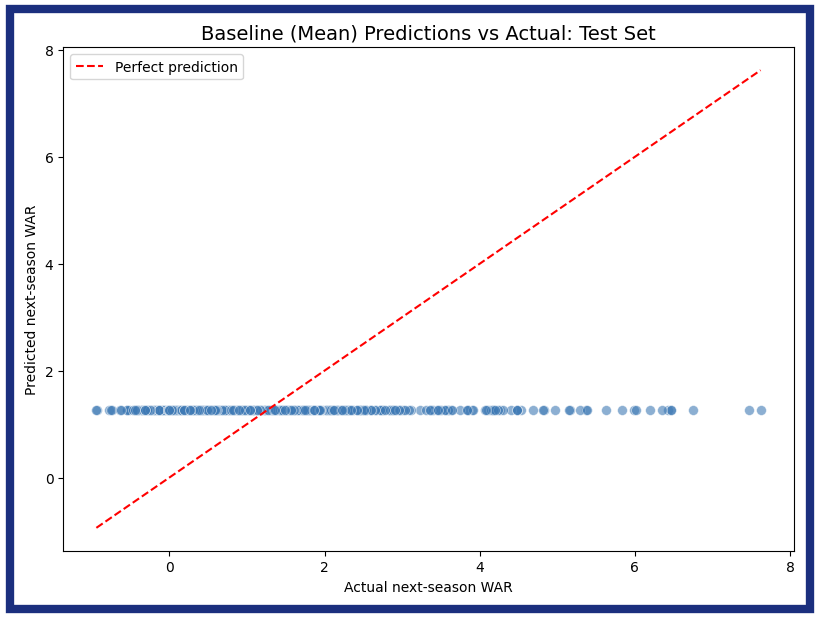

In [6]:
full_pipeline_dummy.fit(X_train, y_train)
y_pred_dummy = full_pipeline_dummy.predict(X_test)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(y_test, y_pred_dummy, color=POINT_BLUE, alpha=0.6,
           edgecolors='white', linewidths=0.5, s=50)
ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label='Perfect prediction')
ax.set_xlabel('Actual next-season WAR')
ax.set_ylabel('Predicted next-season WAR')
ax.set_title('Baseline (Mean) Predictions vs Actual: Test Set', fontsize=14)
ax.legend()
add_border(fig)
plt.tight_layout()
plt.show()

## Decision Tree

In [7]:
full_pipeline_dt = make_pipeline(clone(preprocess), DecisionTreeRegressor(random_state=RANDOM_STATE))

scores_dt = -cross_val_score(full_pipeline_dt, X_train, y_train, groups=groups_train,
                             cv=gkf, scoring='neg_root_mean_squared_error')

print(f'Decision Tree CV RMSE: mean={scores_dt.mean():.4f} std={scores_dt.std():.4f}')

Decision Tree CV RMSE: mean=1.8185 std=0.1098


## Gradient Boosting (tuned)

In [8]:
full_pipeline_gb = make_pipeline(clone(preprocess), GradientBoostingRegressor(random_state=RANDOM_STATE))

param_dist_gb = {
    'gradientboostingregressor__n_estimators': randint(200, 1500),
    'gradientboostingregressor__learning_rate': loguniform(0.005, 0.2),
    'gradientboostingregressor__max_depth': randint(2, 7),
    'gradientboostingregressor__min_samples_leaf': randint(5, 100),
    'gradientboostingregressor__subsample': uniform(0.5, 0.5),          # 0.5–1.0
    'gradientboostingregressor__max_features': [None, 'sqrt', 0.3, 0.5, 0.8],
    'gradientboostingregressor__loss': ['squared_error', 'huber'],
}

grid_gb = RandomizedSearchCV(full_pipeline_gb, param_dist_gb, n_iter=100, cv=gkf,
                             scoring='neg_root_mean_squared_error',
                             random_state=RANDOM_STATE, n_jobs=-1,
                             return_train_score=True)
grid_gb.fit(X_train, y_train, groups=groups_train)

print("Best parameters:", grid_gb.best_params_)
print("Best CV RMSE:", -grid_gb.best_score_)

Best parameters: {'gradientboostingregressor__learning_rate': np.float64(0.0064578948504538354), 'gradientboostingregressor__loss': 'squared_error', 'gradientboostingregressor__max_depth': 3, 'gradientboostingregressor__max_features': 0.8, 'gradientboostingregressor__min_samples_leaf': 39, 'gradientboostingregressor__n_estimators': 926, 'gradientboostingregressor__subsample': np.float64(0.5355943242301144)}
Best CV RMSE: 1.2819413207329509


In [9]:
res = pd.DataFrame(grid_gb.cv_results_).sort_values('rank_test_score').head(10)
res['test_rmse'] = -res['mean_test_score']
res['train_rmse'] = -res['mean_train_score']
res[['test_rmse', 'std_test_score', 'train_rmse'] +
    [c for c in res.columns if c.startswith('param_')]]

,test_rmse,std_test_score,train_rmse,param_gradientboostingregressor__learning_rate,param_gradientboostingregressor__loss,param_gradientboostingregressor__max_depth,param_gradientboostingregressor__max_features,param_gradientboostingregressor__min_samples_leaf,param_gradientboostingregressor__n_estimators,param_gradientboostingregressor__subsample
65,1.281941,0.067913,1.139940,0.006458,squared_error,3,0.8,39,926,0.535594
17,1.282578,0.068512,1.153598,0.012859,squared_error,2,sqrt,46,1091,0.553946
67,1.282683,0.069626,1.196167,0.007732,squared_error,3,0.8,79,612,0.519593
29,1.282915,0.065156,1.218518,0.006976,squared_error,2,0.5,63,663,0.520388
49,1.282953,0.068112,1.122734,0.006030,squared_error,5,sqrt,70,926,0.836013
9,1.283196,0.066234,1.195376,0.009888,squared_error,3,sqrt,48,361,0.697575
48,1.284886,0.069981,1.157665,0.005097,huber,6,0.5,69,711,0.698392
66,1.285004,0.064099,1.172400,0.016218,huber,3,sqrt,38,314,0.640927
13,1.285703,0.068331,1.148472,0.010407,huber,4,0.3,85,591,0.864504
36,1.285911,0.063446,1.201571,0.005173,huber,2,0.3,29,1113,0.580404


## Elastic Net (tuned)

In [10]:
full_pipeline_en = make_pipeline(clone(preprocess), ElasticNet(max_iter=50000, random_state=RANDOM_STATE))

param_grid_en = {
    'elasticnet__alpha': np.logspace(-5, 2, 40),
    'elasticnet__l1_ratio': [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99, 1.0],
    'elasticnet__selection': ['cyclic', 'random'],
}

grid_en = GridSearchCV(full_pipeline_en, param_grid_en, cv=gkf,
                       scoring='neg_root_mean_squared_error',
                       n_jobs=-1, return_train_score=True)
grid_en.fit(X_train, y_train, groups=groups_train)

print("Best parameters:", grid_en.best_params_)
print("Best CV RMSE:", -grid_en.best_score_)

Best parameters: {'elasticnet__alpha': np.float64(0.004923882631706742), 'elasticnet__l1_ratio': 0.95, 'elasticnet__selection': 'cyclic'}
Best CV RMSE: 1.2705679446025617


## CV RMSE Comparison

In [11]:
results_df = pd.DataFrame({
    'Model': ['Baseline (mean)', 'Decision Tree', 'Gradient Boosting (tuned)', 'Elastic Net (tuned)'],
    'CV RMSE Mean': [scores_dummy.mean(), scores_dt.mean(),
                     -grid_gb.best_score_, -grid_en.best_score_],
    'CV RMSE Std': [scores_dummy.std(), scores_dt.std(),
                    grid_gb.cv_results_['std_test_score'][grid_gb.best_index_],
                    grid_en.cv_results_['std_test_score'][grid_en.best_index_]],
})
results_df.sort_values('CV RMSE Mean')

,Model,CV RMSE Mean,CV RMSE Std
3,Elastic Net (tuned),1.270568,0.070210
2,Gradient Boosting (tuned),1.281941,0.067913
0,Baseline (mean),1.547100,0.111458
1,Decision Tree,1.818523,0.109790


                       Model  Train RMSE  Test RMSE
0            Baseline (mean)      1.5505     1.5927
1              Decision Tree      0.0000     1.8658
2  Gradient Boosting (tuned)      1.1544     1.3026
3        Elastic Net (tuned)      1.2603     1.3047


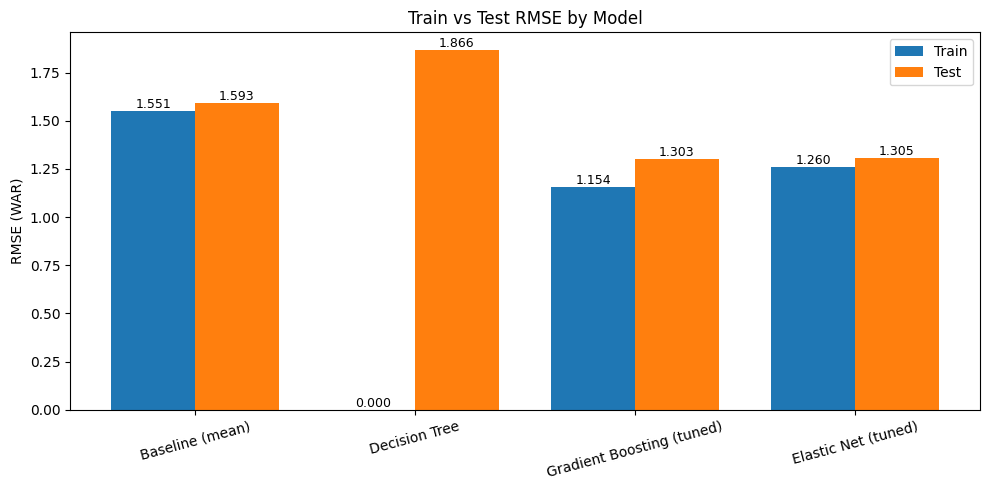

In [12]:
#Fit the untuned pipelines on the full training set
full_pipeline_dummy.fit(X_train, y_train)
full_pipeline_dt.fit(X_train, y_train)

final_models = {
    'Baseline (mean)': full_pipeline_dummy,
    'Decision Tree': full_pipeline_dt,
    'Gradient Boosting (tuned)': grid_gb.best_estimator_,
    'Elastic Net (tuned)': grid_en.best_estimator_,
}

rmse_df = pd.DataFrame({
    'Model': list(final_models.keys()),
    'Train RMSE': [root_mean_squared_error(y_train, m.predict(X_train)) for m in final_models.values()],
    'Test RMSE': [root_mean_squared_error(y_test, m.predict(X_test)) for m in final_models.values()],
})
print(rmse_df.round(4))

#Grouped bar chart
x = np.arange(len(rmse_df))
width = 0.38

fig, ax = plt.subplots(figsize=(10, 5))
train_bars = ax.bar(x - width/2, rmse_df['Train RMSE'], width, label='Train')
test_bars = ax.bar(x + width/2, rmse_df['Test RMSE'], width, label='Test')
ax.bar_label(train_bars, fmt='%.3f', fontsize=9)
ax.bar_label(test_bars, fmt='%.3f', fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(rmse_df['Model'], rotation=15)
ax.set_ylabel('RMSE (WAR)')
ax.set_title('Train vs Test RMSE by Model')
ax.legend()
plt.tight_layout()
plt.show()

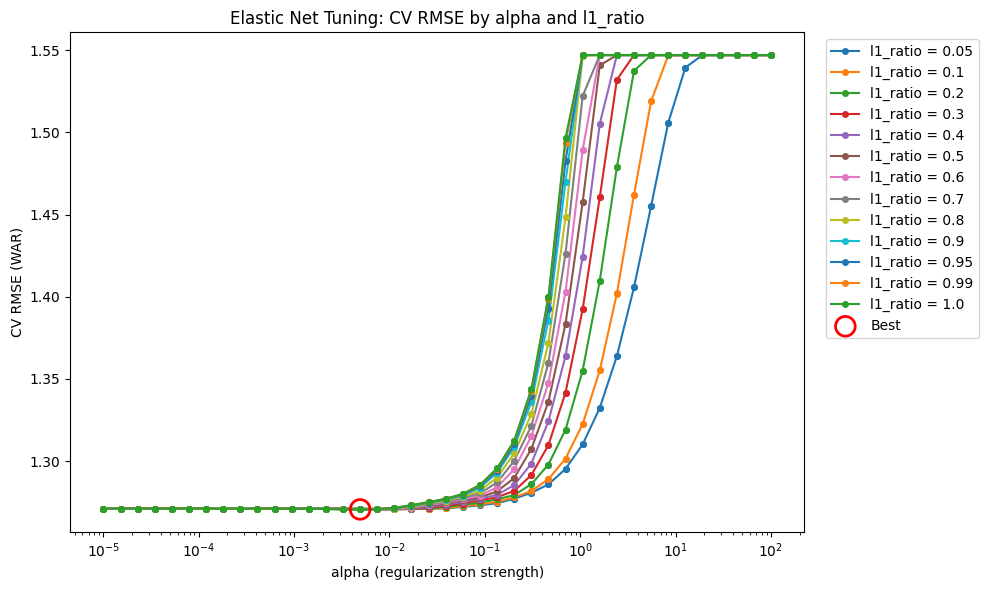

In [13]:
cv_res = pd.DataFrame(grid_en.cv_results_)
cv_res['alpha'] = cv_res['param_elasticnet__alpha'].astype(float)
cv_res['l1_ratio'] = cv_res['param_elasticnet__l1_ratio'].astype(float)
cv_res['cv_rmse'] = -cv_res['mean_test_score']

best_alpha = grid_en.best_params_['elasticnet__alpha']
best_l1 = grid_en.best_params_['elasticnet__l1_ratio']

plt.figure(figsize=(10, 6))
for l1, sub in cv_res.groupby('l1_ratio'):
    sub = sub.sort_values('alpha')
    plt.plot(sub['alpha'], sub['cv_rmse'], marker='o', markersize=4, label=f'l1_ratio = {l1}')
plt.scatter(best_alpha, -grid_en.best_score_, s=200, facecolors='none',
            edgecolors='red', linewidths=2, zorder=5, label='Best')
plt.xscale('log')
plt.xlabel('alpha (regularization strength)')
plt.ylabel('CV RMSE (WAR)')
plt.title('Elastic Net Tuning: CV RMSE by alpha and l1_ratio')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

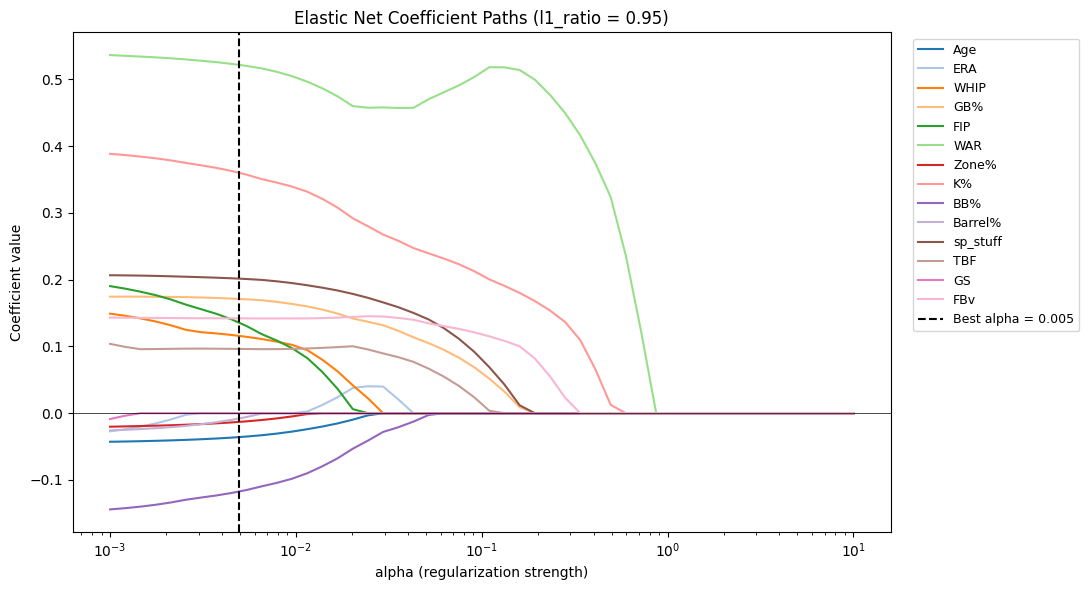

In [14]:
best_en = grid_en.best_estimator_
X_train_prep = best_en.named_steps['columntransformer'].transform(X_train)
feature_names = [n.split('__')[-1] for n in
                 best_en.named_steps['columntransformer'].get_feature_names_out()]

alpha_range = np.logspace(-3, 1, 50)
coefs = []
for a in alpha_range:
    en = ElasticNet(alpha=a, l1_ratio=best_l1, max_iter=10000)
    en.fit(X_train_prep, y_train)
    coefs.append(en.coef_)
coefs = np.array(coefs)

plt.figure(figsize=(11, 6))
for i in range(coefs.shape[1]):
    plt.plot(alpha_range, coefs[:, i], label=feature_names[i], color=plt.cm.tab20(i))
plt.axvline(best_alpha, color='black', linestyle='--', label=f'Best alpha = {best_alpha:.3f}')
plt.axhline(0, color='black', linewidth=0.5)
plt.xscale('log')
plt.xlabel('alpha (regularization strength)')
plt.ylabel('Coefficient value')
plt.title(f'Elastic Net Coefficient Paths (l1_ratio = {best_l1})')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

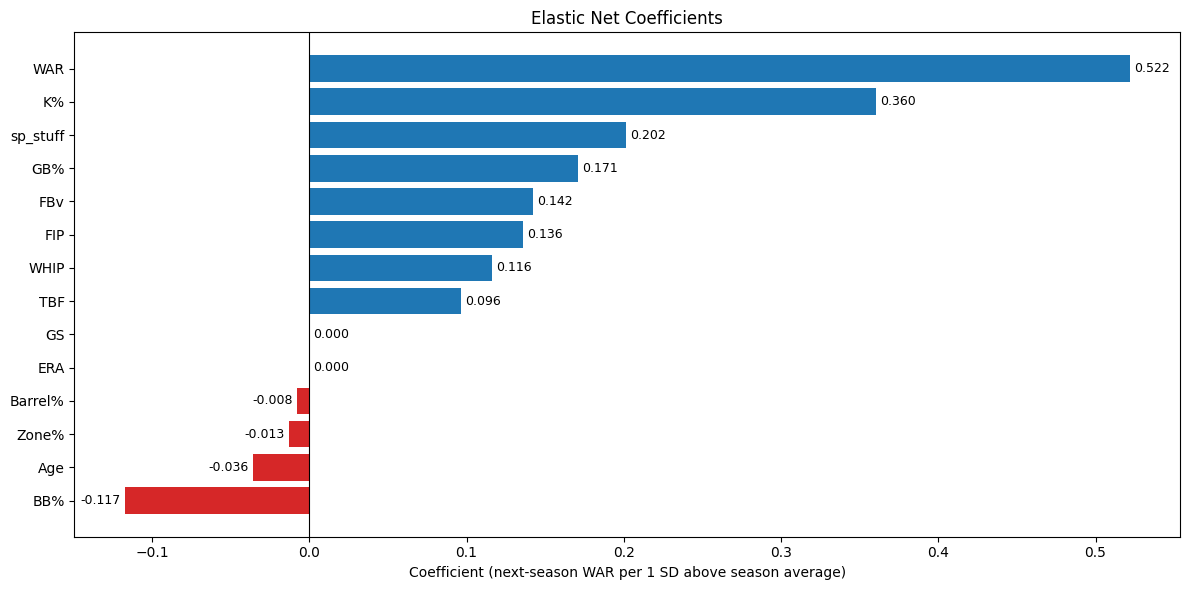

Intercept: 1.192
Features dropped to 0: ['ERA', 'GS']


In [15]:
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': best_en.named_steps['elasticnet'].coef_,
}).sort_values('Coefficient')

colors = ['tab:red' if c < 0 else 'tab:blue' for c in coef_df['Coefficient']]

plt.figure(figsize=(12, 6))
bars = plt.barh(coef_df['Feature'], coef_df['Coefficient'], color=colors)
plt.bar_label(bars, fmt='%.3f', padding=3, fontsize=9)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Coefficient (next-season WAR per 1 SD above season average)')
plt.title('Elastic Net Coefficients')
plt.tight_layout()
plt.show()

print('Intercept:', round(best_en.named_steps['elasticnet'].intercept_, 3))
print('Features dropped to 0:', list(coef_df.loc[coef_df['Coefficient'] == 0, 'Feature']))

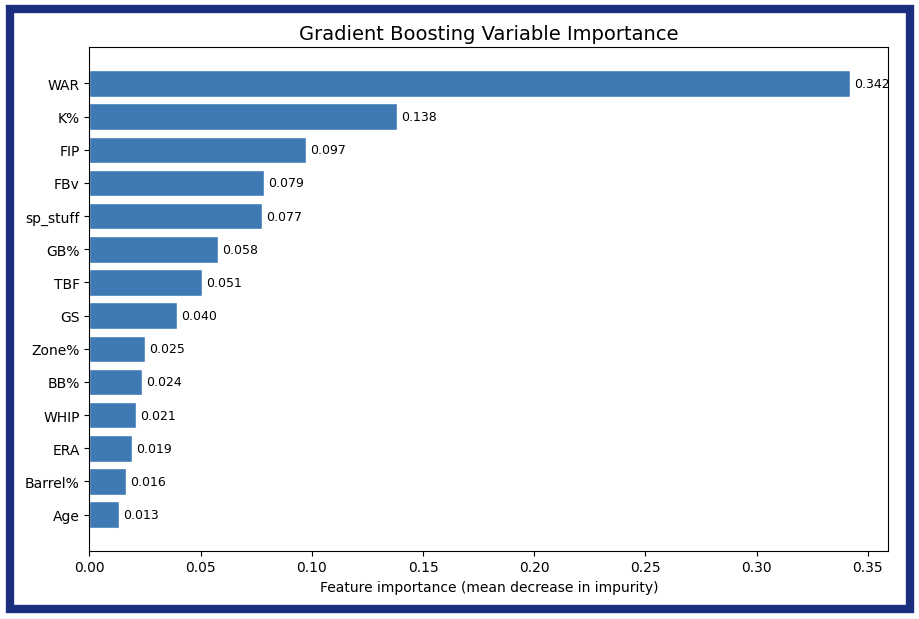

In [16]:
best_gb = grid_gb.best_estimator_
gb_names = [n.split('__')[-1] for n in
            best_gb.named_steps['columntransformer'].get_feature_names_out()]

gb_imp = pd.Series(best_gb.named_steps['gradientboostingregressor'].feature_importances_,
                   index=gb_names).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(gb_imp.index, gb_imp.values, color=POINT_BLUE, edgecolor='white')
ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=9)
ax.set_xlabel('Feature importance (mean decrease in impurity)')
ax.set_title('Gradient Boosting Variable Importance', fontsize=14)
add_border(fig)
plt.tight_layout()
plt.show()

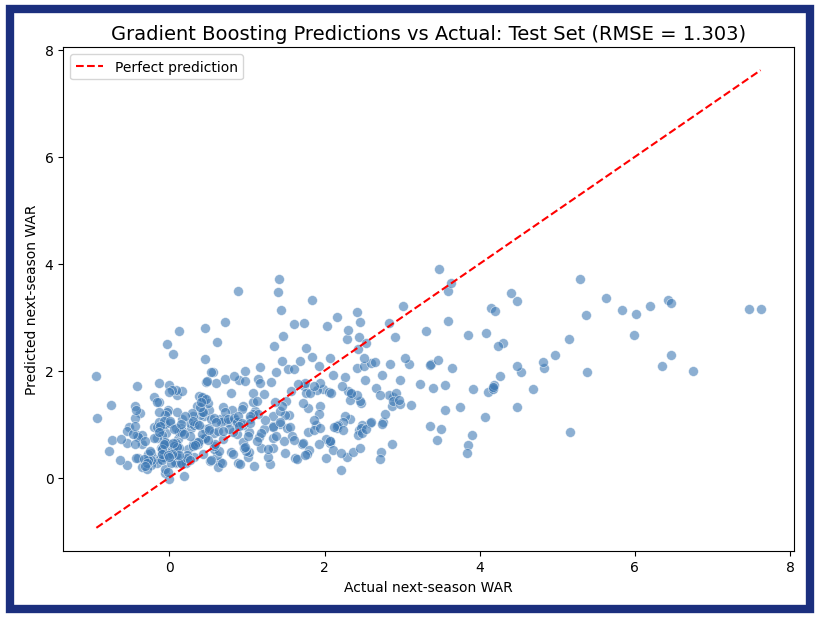

In [17]:
y_pred_gb = best_gb.predict(X_test)
gb_test_rmse = root_mean_squared_error(y_test, y_pred_gb)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(y_test, y_pred_gb, color=POINT_BLUE, alpha=0.6,
           edgecolors='white', linewidths=0.5, s=50)
ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label='Perfect prediction')
ax.set_xlabel('Actual next-season WAR')
ax.set_ylabel('Predicted next-season WAR')
ax.set_title(f'Gradient Boosting Predictions vs Actual: Test Set (RMSE = {gb_test_rmse:.3f})', fontsize=14)
ax.legend()
add_border(fig)
plt.tight_layout()
plt.show()

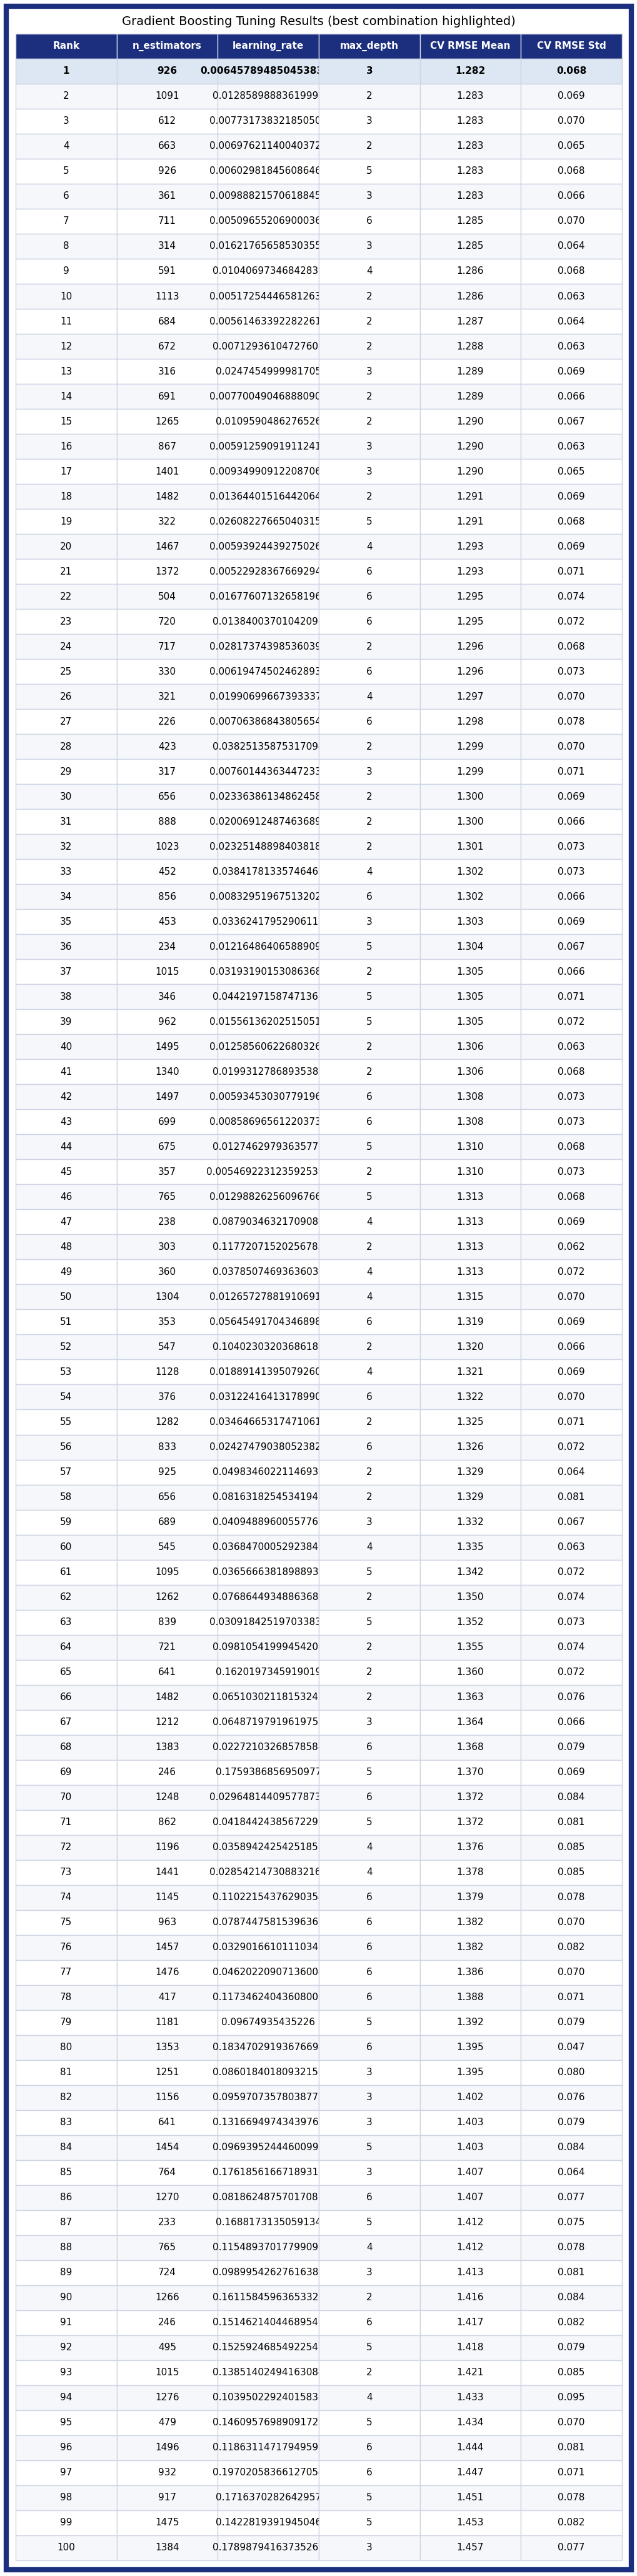

In [18]:
gb_res = pd.DataFrame(grid_gb.cv_results_)

gb_table = pd.DataFrame({
    'Rank': gb_res['rank_test_score'],
    'n_estimators': gb_res['param_gradientboostingregressor__n_estimators'].astype(int),
    'learning_rate': gb_res['param_gradientboostingregressor__learning_rate'].astype(float),
    'max_depth': gb_res['param_gradientboostingregressor__max_depth'].astype(int),
    'CV RMSE Mean': (-gb_res['mean_test_score']).round(3),
    'CV RMSE Std': gb_res['std_test_score'].round(3),
}).sort_values('Rank').reset_index(drop=True)

cell_text = gb_table.assign(**{
    'CV RMSE Mean': gb_table['CV RMSE Mean'].map('{:.3f}'.format),
    'CV RMSE Std': gb_table['CV RMSE Std'].map('{:.3f}'.format),
}).astype(str).values

fig, ax = plt.subplots(figsize=(10, 0.4 * len(gb_table) + 1))
ax.axis('off')

tbl = ax.table(cellText=cell_text, colLabels=gb_table.columns,
               cellLoc='center', bbox=[0, 0, 1, 1])
tbl.auto_set_font_size(False)
tbl.set_fontsize(11)

for (row, col), cell in tbl.get_celld().items():
    cell.set_edgecolor('#D0D5E5')
    if row == 0:
        cell.set_facecolor(NAVY)
        cell.set_text_props(color='white', weight='bold')
    elif row == 1:
        cell.set_facecolor('#DCE7F3')
        cell.set_text_props(weight='bold')
    elif row % 2 == 0:
        cell.set_facecolor('#F5F7FB')

ax.set_title('Gradient Boosting Tuning Results (best combination highlighted)', fontsize=14, pad=10)
add_border(fig)
plt.tight_layout()
plt.show()

## Feature Set Comparison: Selected vs Expanded vs Expanded + PCA

In [19]:
#Dropped 'selection' here to keep the PCA grid a manageable size
param_grid_en_cmp = {
    'elasticnet__alpha': np.logspace(-5, 2, 30),
    'elasticnet__l1_ratio': [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99, 1.0],
}

def run_feature_set(cols, use_pca=False):
    X_tr, X_te = X_train_full[cols], X_test_full[cols]

    front = [make_preprocess(cols)]
    pca_grid = {}
    if use_pca:
        front += [StandardScaler(), PCA(random_state=RANDOM_STATE)]
        pca_grid = {'pca__n_components': [3, 5, 8, 10, 15, 20, 0.80, 0.90, 0.95]}

    def pipe(model):
        return make_pipeline(*[clone(s) for s in front], model)

    cv_args = dict(cv=gkf, scoring='neg_root_mean_squared_error', n_jobs=-1)
    out = {}

    #Untuned models (same as above)
    for name, model in [('Baseline (mean)', DummyRegressor(strategy='mean')),
                        ('Decision Tree', DecisionTreeRegressor(random_state=RANDOM_STATE))]:
        p = pipe(model)
        cv = -cross_val_score(p, X_tr, y_train, groups=groups_train, **cv_args)
        out[name] = (p.fit(X_tr, y_train), cv.mean(), cv.std())

    #Tuned models (PCA n_components tuned jointly when use_pca=True)
    gb = RandomizedSearchCV(pipe(GradientBoostingRegressor(random_state=RANDOM_STATE)),
                            {**param_dist_gb, **pca_grid}, n_iter=100,
                            random_state=RANDOM_STATE, **cv_args)
    en = GridSearchCV(pipe(ElasticNet(max_iter=50000, random_state=RANDOM_STATE)),
                      {**param_grid_en_cmp, **pca_grid}, **cv_args)

    for name, s in [('Gradient Boosting (tuned)', gb), ('Elastic Net (tuned)', en)]:
        s.fit(X_tr, y_train, groups=groups_train)
        out[name] = (s.best_estimator_, -s.best_score_,
                     s.cv_results_['std_test_score'][s.best_index_])

    rows = [{'Model': name, 'CV RMSE Mean': cv_mean, 'CV RMSE Std': cv_std,
             'Train RMSE': root_mean_squared_error(y_train, m.predict(X_tr)),
             'Test RMSE': root_mean_squared_error(y_test, m.predict(X_te))}
            for name, (m, cv_mean, cv_std) in out.items()]

    return pd.DataFrame(rows), {'gb': gb, 'en': en}

In [20]:
feature_sets = {
    f'Selected ({len(predictors)})': (predictors, False),
    f'Expanded ({len(predictors_full)})': (predictors_full, False),
    'Expanded + PCA': (predictors_full, True),
}

all_results, searches = [], {}
for fs_name, (cols, use_pca) in feature_sets.items():
    res_fs, searches[fs_name] = run_feature_set(cols, use_pca)
    all_results.append(res_fs.assign(**{'Feature Set': fs_name}))
    print(fs_name, 'done')

comparison = pd.concat(all_results, ignore_index=True)

cv_wide = comparison.pivot(index='Model', columns='Feature Set', values='CV RMSE Mean')[list(feature_sets)]
test_wide = comparison.pivot(index='Model', columns='Feature Set', values='Test RMSE')[list(feature_sets)]
print('CV RMSE\n', cv_wide.round(4), '\n')
print('Test RMSE\n', test_wide.round(4), '\n')

for fs_name, s in searches.items():
    print(f'{fs_name} | GB best: {s["gb"].best_params_}')
    print(f'{fs_name} | EN best: {s["en"].best_params_}\n')

Selected (14) done
Expanded (64) done
Expanded + PCA done
CV RMSE
 Feature Set                Selected (14)  Expanded (64)  Expanded + PCA
Model                                                                  
Baseline (mean)                   1.5471         1.5471          1.5471
Decision Tree                     1.8185         1.8477          1.8714
Elastic Net (tuned)               1.2706         1.2714          1.2790
Gradient Boosting (tuned)         1.2819         1.2814          1.3069 

Test RMSE
 Feature Set                Selected (14)  Expanded (64)  Expanded + PCA
Model                                                                  
Baseline (mean)                   1.5927         1.5927          1.5927
Decision Tree                     1.8658         1.8262          1.7956
Elastic Net (tuned)               1.3046         1.3142          1.3166
Gradient Boosting (tuned)         1.3026         1.3120          1.3342 

Selected (14) | GB best: {'gradientboostingregressor__

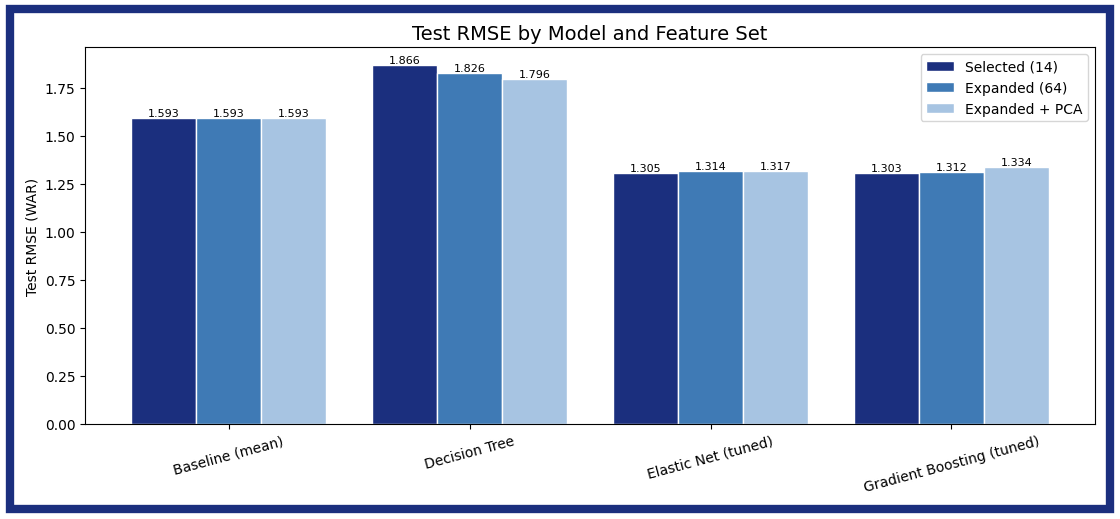

In [21]:
#Grouped bar chart: test RMSE by model and feature set
x = np.arange(len(test_wide))
width = 0.27

fig, ax = plt.subplots(figsize=(11, 5))
for i, (fs, color) in enumerate(zip(test_wide.columns, [NAVY, POINT_BLUE, '#A7C4E2'])):
    bars = ax.bar(x + (i - 1) * width, test_wide[fs], width, label=fs, color=color, edgecolor='white')
    ax.bar_label(bars, fmt='%.3f', fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(test_wide.index, rotation=15)
ax.set_ylabel('Test RMSE (WAR)')
ax.set_title('Test RMSE by Model and Feature Set', fontsize=14)
ax.legend()
add_border(fig)
plt.tight_layout()
plt.show()

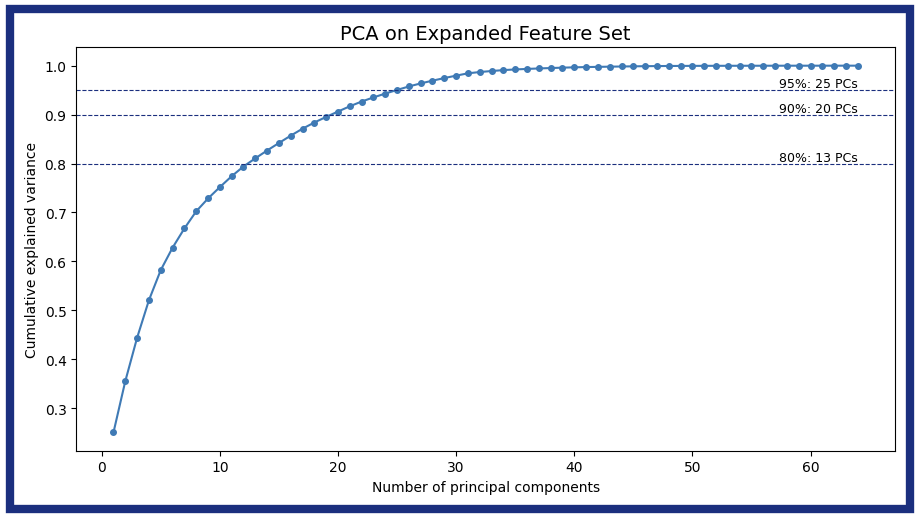

In [22]:
#PCA cumulative explained variance (justifies the n_components options)
pca_check = make_pipeline(make_preprocess(predictors_full), StandardScaler(), PCA()).fit(X_train_full)
cum_var = np.cumsum(pca_check.named_steps['pca'].explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(np.arange(1, len(cum_var) + 1), cum_var, marker='o', markersize=4, color=POINT_BLUE)
for t in [0.80, 0.90, 0.95]:
    ax.axhline(t, color=NAVY, linestyle='--', linewidth=0.8)
    ax.text(len(cum_var), t, f' {t:.0%}: {np.argmax(cum_var >= t) + 1} PCs', va='bottom', ha='right', fontsize=9)
ax.set_xlabel('Number of principal components')
ax.set_ylabel('Cumulative explained variance')
ax.set_title('PCA on Expanded Feature Set', fontsize=14)
add_border(fig)
plt.tight_layout()
plt.show()